In [1]:
print("My Data Analytics Portfolio")
print("Project 1: Sales Data Analysis")
print("Tools: Python, Pandas, Power BI")

My Data Analytics Portfolio
Project 1: Sales Data Analysis
Tools: Python, Pandas, Power BI


In [3]:
import pandas as pd
df = pd.read_csv("sample-Superstore.csv", encoding= "latin1")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'sample-Superstore.csv'

###### import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

In [5]:
import pandas as pd

df = pd.read_csv("Sample - Superstore.csv.csv", encoding="latin1")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [7]:
print ("Dataset size:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values per column:")
print(df.isnull().sum())

Dataset size: (9994, 21)

Column names:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

Missing values per column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [9]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")

Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009


In [10]:
category_performance = df.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Units_Sold=("Quantity", "sum")
).round(2)

category_performance = category_performance.sort_values(
    by="Total_Profit", ascending=False
)

category_performance

,Total_Sales,Total_Profit,Units_Sold
Category,,,
Technology,836154.03,145454.95,6939
Office Supplies,719047.03,122490.80,22906
Furniture,741999.80,18451.27,8028


Matplotlib is building the font cache; this may take a moment.


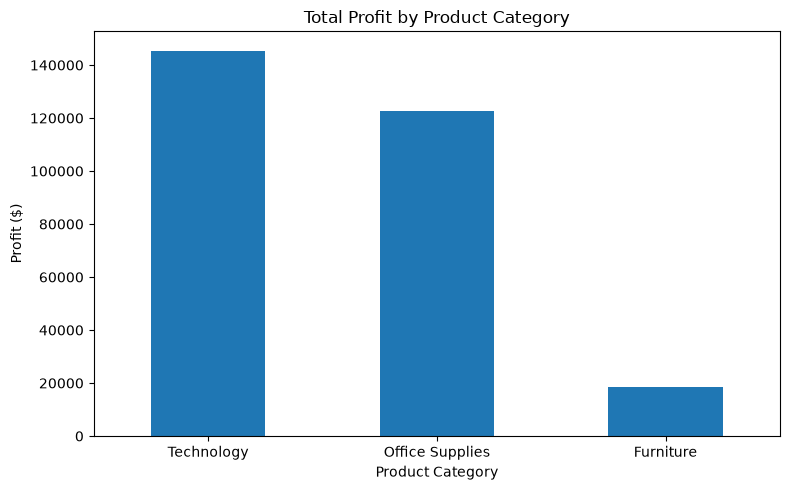

In [11]:
import matplotlib.pyplot as plt

category_performance["Total_Profit"].plot(
    kind="bar",
    figsize=(8, 5),
    title="Total Profit by Product Category"
)

plt.xlabel("Product Category")
plt.ylabel("Profit ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [12]:
top_products = df.groupby("Product Name").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum")
)

top_products = top_products.sort_values(
    by="Total_Sales", ascending=False
)

top_products.head(10).round(2)

,Total_Sales,Total_Profit
Product Name,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08
HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00
GBC DocuBind TL300 Electric Binding System,19823.48,2233.51
GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17


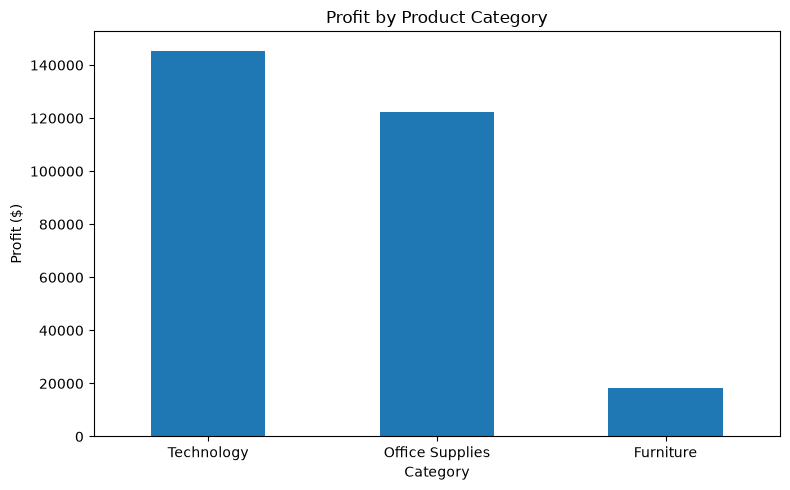

Portfolio results saved successfully!


In [13]:
import os

os.makedirs("outputs", exist_ok=True)

category_performance.to_csv(
    "outputs/category_performance.csv"
)

top_products.head(10).to_csv(
    "outputs/top_10_products.csv"
)

plt.figure(figsize=(8, 5))
category_performance["Total_Profit"].plot(kind="bar")
plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("outputs/profit_by_category.png", dpi=300)
plt.show()

print("Portfolio results saved successfully!")

In [14]:
report = """
SALES DATA ANALYSIS REPORT

1. PROJECT OVERVIEW
Analyzed 9,994 sales records to understand business performance,
product category profitability, and top-selling products.

2. KEY BUSINESS METRICS
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Unique Orders: 5,009

3. CATEGORY INSIGHTS
Technology generated the highest profit at $145,454.95.
Office Supplies generated $122,490.80 in profit.
Furniture generated only $18,451.27 despite substantial sales.

4. PRODUCT INSIGHT
The Cisco TelePresence System EX90 generated $22,638.48 in sales
but recorded a loss of $1,811.08.

5. RECOMMENDATIONS
Investigate furniture discounts, costs, and product margins.
Review products with high sales but negative profit.
Continue monitoring category-level profitability.

6. TOOLS USED
Python, Pandas, Matplotlib, Jupyter Notebook.
"""

with open("outputs/sales_analysis_report.txt", "w", encoding="utf-8") as file:
    file.write(report)

print("Business report saved successfully!")

Business report saved successfully!
